# Stage 4: the pixels

**The question.** Does the first frame predict a video's lift, beyond who made the video and what it says? `lift` is
stage 1's target: the video's log share rate minus the median of its creator's last 30 videos posted at least 14 days
earlier. Who made the video is in the target already, B3 (stage 2: the video's length and timing) and the text model
(stage 3: seven text fields in ridge on top of B3) say the rest, and this stage asks what the frame adds to them.

Two sets of embeddings come back from one rented GPU (`docs/gpu.md`):

- **The text, a second time:** Qwen3-Embedding-4B over the seven text fields, the larger encoder notebook 03's hand-off
  sent to the rental, with its bar written there. It is scored first: the better of it and bge-small is the reference
  the pixels must beat.
- **The frames:** one per video, made in stage 4's prep (`notebooks/04_frames.ipynb`) by the platform's own poster
  code, so a kept clip's frame and a retired clip's poster can't be told apart by how they were made (trap 3).

**The image encoder: SigLIP 2, so400m, patch 14, 384 px** (`google/siglip2-so400m-patch14-384`), frozen: 1,152
numbers per frame. Why this one:

- **It learned from images and their captions,** like CLIP, so its numbers describe what a picture shows: people,
  places, objects, text. That is this stage's question. A self-supervised encoder such as DINOv2 learns what makes two
  pictures look alike (the room, the light, the camera), which is closer to who filmed the video than to what works.
- **It sees the whole frame.** Its own preprocessing squashes the 9:16 frame into a 384×384 square. CLIP's resizes the
  short side and keeps the centre square, which cuts 22% off the top and 22% off the bottom of a vertical video, where
  the hook and the captions usually sit; stage 3 found on-screen text the strongest single field.
- **It is the strongest of its kind that the rental runs cheaply.** The SigLIP 2 paper reports it ahead of the first
  SigLIP at every size, in classification and retrieval without fine-tuning, and the first SigLIP was already ahead of
  CLIP. so400m is its largest size short of the 1-billion-parameter one: about 400 million parameters in the image
  tower, so one RTX 3090 embeds every frame in float32 in about 75 minutes (estimated from the model's size, not
  measured), and 1,152 numbers keep every head on this laptop.
- **Frozen first.** It is the same model class and preprocessing as the SigLIP 2 base the GPU kit was tested with
  (`docs/gpu.md`, section 6), so the box runs code that already ran. Fine-tuning comes only if the frozen vectors pass.

**The rental, estimated before it** (`docs/gpu.md`, section 4): 2× RTX 3090, the 4B text job about 2 to 5 hours on both
cards, the frames about 40 minutes on both, about 3 to 6.5 hours and $1 to $2.50 in all. Section 1 records what it took.

The code is `src/sharerate/` (the loader, the text cache, the frames, the bootstrap and the metrics), with the heads
written out in the cells, as in notebook 03.

## 0. The bar, written before the rental (rule 7)

This cell was written, and committed, before the box was rented: no Qwen3-Embedding-4B or SigLIP 2 so400m vector
of these videos existed yet.

**Part A. The text: Qwen3-Embedding-4B against bge-small.** Notebook 03's hand-off wrote this bar before the 4B ran. It
is applied as written and never re-decided:

- Qwen3-Embedding-4B (its first 1,024 numbers, from the first 256 tokens, unit length, no instruction) replaces
  bge-small if the 95% paired creator-bootstrap interval of its ridge head's validation MAE gain over bge ridge lies
  above 0 for **seen** creators (138, 13,646 videos), **with and without the 73 reposts**. Both heads sit on top of B3,
  with notebook 03's `ridge_head`, on the same 21,332 validation rows, 2,000 draws, seed 2026. Otherwise bge-small
  stays.
- The 4B ridge's penalty is chosen on validation as bge's was, over notebook 03's grid (10 to 10,000). If the choice
  lands on an end of the grid, the grid gets one more step that way (a factor of about 3), and the notebook says so.
- The 4B's logistic head (C chosen by validation ROC-AUC, as in notebook 03) is reported, not judged. It goes to
  stage 5 only if the 4B wins.
- **The winner is the reference** for everything below: B3 ridge plus the winning text head.

**Part B. The pixels: does the frame add to the reference?**

- **The rows.** Only rows with a frame (`notebooks/04_frames.ipynb`, cell 4). Models are fitted on the 74,518 training
  rows that have one (of 74,552) and scored on the 21,328 validation rows that have one (of 21,332: 13,645 of the seen
  creators', 2,274 of the new ones', 5,409 of the held-out ones'). The reference is re-scored on exactly these rows
  (rule 5). The rows without a frame are counted, and compared in lift if they come from at least 5 creators.
- **The reference on the training rows is out of fold.** The image heads are fitted to what the reference leaves on
  the training rows. The text head has thousands of columns and was fitted on those same rows, so its residuals there
  are smaller than the ones it leaves on videos it never saw, and an image head fitted to them would learn from
  residuals that are too clean. So B3 and the text head are refitted in 5 folds grouped by creator, with their
  penalties fixed, and each training row gets the reference from a fit that never saw its creator. Validation rows get
  the full fit: the model Part A scored.
- **Image ridge.** SigLIP 2's 1,152 numbers, scaled to unit length, in ridge fitted on the training rows to what the
  reference leaves. The prediction is the reference plus the head. Its penalty is chosen by validation MAE over all
  21,328 validation rows with a frame, from 1 to 10,000 in steps of about 3, with the same one-more-step rule at an
  end.
- **Image boosting,** the small non-linear model: scikit-learn's `HistGradientBoostingRegressor` on the first 64
  principal components of the unit vectors (fitted on the training rows) and the reference's prediction, fitted to
  what the reference leaves. The prediction is the reference plus its output. Fixed now: learning rate 0.05, at most 15
  leaves a tree, at least 200 videos a leaf, an L2 penalty of 1, squared error, seed 2026. Only the number of trees (25
  to 1,000, in steps of 25) is chosen, by validation MAE. **Its control** is the same model on the reference's
  prediction alone: boosting can bend the reference by itself, and that bend is not the frame's. The boosting's gain
  is measured over its control.
- **The primary bar.** An image model beats the reference if the 95% paired creator-bootstrap interval (2,000 draws,
  seed 2026) of its validation MAE gain over its base (the reference for the ridge, the control for the boosting) lies
  above 0 for **seen** creators, **with and without the reposts**.
- **Does a frame name its creator? This decides the metric.** A logistic regression on the standardised unit vectors
  (C 1, fixed now), fitted on the training frames to name each frame's creator (148 creators), names the creator of
  each seen creator's validation frame. If its top-1 accuracy is at least 5 times what always guessing the biggest
  creator scores, frames identify their creators well, and a pixel model could gain by learning who made a video,
  which lift already accounts for. Then a pass also needs the gain in Spearman inside a creator (over the same base,
  seen creators) to have an interval above 0: a model that only knew the creator would rank nothing inside one.
- **The leak check, stage 3's, on the pixels.** Inside each creator, the image model's correction (its prediction
  minus its base's) is regressed on whether the platform kept the clip and on the lift (notebook 03's
  `kept_given_lift`, seen creators). If the kept flag's interval lies above 0, the model finds kept clips by something
  other than the lift, and it is reported as a leak, not a pass, whatever its gain. Spearman inside a creator among
  kept clips alone and among retired clips alone is reported beside it.
- **Reported, not required:** new and held-out creators; ROC-AUC, PR-AUC and the top-10% share.
- **Fine-tuning runs only if a frozen image model passes** everything above. Then a second rental fine-tunes SigLIP 2's
  image tower, or a light adapter on it, on the training rows to the same target, stopping when validation MAE stops
  improving, with every run logged to an MLflow file store. It replaces the frozen model only if its MAE gain over that
  model has an interval above 0 for seen creators, with and without the reposts.
- **What goes to stage 5.** Part A's text winner, and the passing image model with the largest MAE gain for seen
  creators. If no image model passes, stage 5 leaves the pixels out, and this notebook says the first frame adds
  nothing beyond who made the video and what it says. That result is publishable.
- **Fixed in advance, never tuned:** the encoder and its preprocessing (float32, the whole frame squashed to 384×384 by
  its own processor), unit length, the 64 components, the boosting's settings, the creator probe's, the 5 folds, the
  seeds. **Chosen on validation:** the ridge penalties, the logistic C and the number of trees. The test split stays
  closed; stage 5 opens it once.
- **A miss is a miss.** A gain whose interval touches 0 is reported as a miss, never tuned until it passes.

## 1. The rental

**What.** What the box ran, read from the job's own log (`runs.jsonl`: one line per run, with the card, the rows, the
seconds and the library versions), fetched back with the vectors into `data/gpu/inbox/` (git-ignored).

**Why.** Rule 8: the hours in the README come from a file, and the cost from vast.ai's bill, not from memory or from
the estimate in cell 0.

**The mistake it avoids.** Quoting the estimate as if it were the measurement. The box's address is in the folder's
name, so the cell reads it and never prints it.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sharerate import data, frames, history, text
from sharerate.bootstrap import paired_creator_bootstrap
from sharerate.heads import RidgeGram
from sharerate.metrics import METRICS, eligible_creators

SEED, N_BOOT = 2026, 2_000  # stages 2 and 3's seed: the same 2,000 creator draws
GROUPS = ["seen", "new", "holdout"]  # targets.creator_seen, rule 3's three ways
GROUP_NAMES = {"seen": "Seen creators", "new": "New creators (training group, no training rows)",
               "holdout": "Held-out creators"}
FIELDS = list(text.FIELDS)  # caption, transcript, hook, body, payoff, on-screen text, scene description
QWEN = "Qwen/Qwen3-Embedding-4B"  # the text job's encoder (notebook 03's hand-off)
SIGLIP = "google/siglip2-so400m-patch14-384"  # the frame job's encoder (cell 0)
MIN_CREATORS = 5  # rule 9: no number is shown for fewer than 5 creators
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

runs = []
for log in sorted((data.ROOT / "data" / "gpu" / "inbox").glob("*/out/*/*/runs.jsonl")):
    if log.parts[-5] != "local":  # data/gpu/inbox/<box>/out/<job>/<model>/runs.jsonl; "local" is the laptop test
        runs += [json.loads(line) for line in log.read_text(encoding="utf-8").splitlines()]
runs = pd.DataFrame(runs)
if len(runs):
    runs["started"] = pd.to_datetime(runs.finished) - pd.to_timedelta(runs.seconds, unit="s")
    runs["per second"] = (runs.rows / runs.seconds).round(1)
    display(runs[["job", "model", "shard", "device", "card", "dtype", "rows", "seconds", "per second"]])
    for job, part in runs.groupby("job"):
        wall = (pd.to_datetime(part.finished).max() - part.started.min()).total_seconds()
        print(f"{job}, the runs that finished: {part.rows.sum():,} vectors, {part.seconds.sum() / 3600:.2f} card-hours, "
              f"{wall / 3600:.2f} hours from their first start to their last finish")
    # A run that dies writes its parts but never its line, so the cache is the count of what the text job made
    in_cache = len(text._read_cache(text.EMBEDDING_CACHE / QWEN.replace("/", "--")))
    print(f"text, every run: {in_cache:,} vectors in the cache, {in_cache - runs[runs.job == 'text'].rows.sum():,} "
          f"of them from runs that stopped before writing their line")
else:
    print("No rental log in data/gpu/inbox: fetch the vectors first (docs/gpu.md, step 6)")

,job,model,shard,device,card,dtype,rows,seconds,per second
0,frames,google/siglip2-so400m-patch14-384,0/2,cuda:0,NVIDIA GeForce RTX 3090,float32,72177,3190.8,22.6
1,frames,google/siglip2-so400m-patch14-384,1/2,cuda:1,NVIDIA GeForce RTX 3090,float32,71264,3091.0,23.1
2,text,Qwen/Qwen3-Embedding-4B,0/2,cuda:0,NVIDIA GeForce RTX 3090,float32,32598,1940.4,16.8
3,text,Qwen/Qwen3-Embedding-4B,1/2,cuda:1,NVIDIA GeForce RTX 3090,float32,32357,1937.5,16.7


frames, the runs that finished: 143,441 vectors, 1.74 card-hours, 1.01 hours from their first start to their last finish
text, the runs that finished: 64,955 vectors, 1.08 card-hours, 0.68 hours from their first start to their last finish


text, every run: 644,955 vectors in the cache, 580,000 of them from runs that stopped before writing their line


**What it says.** Both cards were RTX 3090s, and every job ran in float32. The frames took 1.01 hours from the first
start to the last finish, at 22.6 and 23.1 frames a second a card: 1.74 card-hours for 143,441 vectors. The text job's
log holds only the two runs that finished, the last 32,598 and 32,357 texts at 16.8 and 16.7 a second. The other
580,000 vectors came from the first two runs, which ran out of memory at batch 64 on the longest texts (both at 290,000
of their 322,000, the texts going shortest first): they had saved their parts, wrote no line, and the job resumed at
batch 32 (`docs/gpu.md`). The text job ran from 10:00 to 12:06 UTC, about 2.1 hours, and the
whole rental, from the box's start at 09:49 UTC to its destruction after the 13:00 wipe, about 3.2 hours. The bill
wasn't read, so the cost is an estimate: two cards for 3.2 hours at $0.13 to $0.20 a card-hour, about $0.85 to $1.30.

## 2. The rows

**What.** Load the training and validation rows with their text fields, as notebook 03 did, and which of them have a
frame (`frames.frame_ids`, the same rows in the same order). Then split the training creators into the 5 folds the
out-of-fold reference uses (section 0), every creator's videos in one fold.

**Why.** Part A scores the text on all 21,332 validation rows, stage 3's rows. Part B scores the pixels on the rows
with a frame, and rule 5 asks how the rows without one differ: here, in their mean lift against the rest's, with an
interval from draws of creators, since they come from more than 5 creators (section 0).

**The mistake it avoids.** Reading where a frame came from (a video file or a poster). That is `has_video`, the leak,
under another name: `frames.frame_ids` returns only whether a row has a frame, never its source.

In [2]:
videos = data.load_videos(text=True)  # train and validation only; the text columns are never printed
posts = data.load_posting_times()  # B3's timing features
training = ((videos.time_split == "train") & (videos.creator_group == "train")).to_numpy()  # the only rows fitted on
validation = (videos.time_split == "validation").to_numpy()  # every setting is chosen here
lift = videos.lift.to_numpy()
breakout = videos.breakout.to_numpy().astype(int)
creator = videos.creator.to_numpy()
group = videos.creator_seen.to_numpy()
twin = videos.has_twin.to_numpy() == 1  # has_twin is 0/1: compare, never ~, which flips bits
has_frame = frames.frame_ids().notna().to_numpy()  # load_videos' rows, in its order
assert len(has_frame) == len(videos)

# The 5 folds, fixed before any model: GroupKFold keeps each training creator's videos in one fold
folds = np.full(len(videos), -1)
train_index = np.flatnonzero(training)
for k, (_, part) in enumerate(GroupKFold(n_splits=5).split(train_index, groups=creator[train_index])):
    folds[train_index[part]] = k

cells = {"training": training} | {f"validation: {g}": validation & (group == g) for g in GROUPS}
display(pd.DataFrame({name: {"videos": rows.sum(), "creators": len(set(creator[rows])),
                             "with a frame": (rows & has_frame).sum(), "reposts (has_twin)": (rows & twin).sum()}
                      for name, rows in cells.items()}).T)
display(pd.DataFrame({"creators": [len(set(creator[folds == k])) for k in range(5)],
                      "videos": [(folds == k).sum() for k in range(5)]}, index=[f"fold {k}" for k in range(5)]).T)

# Notebook 03's rows, and notebook 04_frames' frames (its cell 4): if these move, the rows are not the same.
assert (training.sum(), len(set(creator[training]))) == (74_552, 148)
assert (validation & has_frame).sum() == 21_328 and (training & has_frame).sum() == 74_518
assert [(validation & has_frame & (group == g)).sum() for g in GROUPS] == [13_645, 2_274, 5_409]

without = (training | validation) & ~has_frame
print(f"Rows without a frame: {without.sum()} ({(training & ~has_frame).sum()} training, "
      f"{(validation & ~has_frame).sum()} validation), from {len(set(creator[without]))} creators")
if len(set(creator[without])) >= MIN_CREATORS:
    # Their mean lift minus the rest's, with an interval from 2,000 draws of creators (as notebook 04_frames, cell 6)
    both = training | validation
    codes, _ = pd.factorize(creator[both])
    n = codes.max() + 1
    mask, values = without[both], lift[both]
    sums = {name: (np.bincount(codes, values * m, n), np.bincount(codes, m * 1.0, n))  # per creator: lift total, count
            for name, m in (("without", mask), ("with", ~mask))}
    rng = np.random.default_rng(SEED)
    draws = np.stack([np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)])
    mean = {name: (draws @ total) / (draws @ count) for name, (total, count) in sums.items()}
    low, high = np.nanquantile(mean["without"] - mean["with"], [0.025, 0.975])  # a draw with none of them gives nan
    print(f"Their mean lift minus the rest's: {values[mask].mean() - values[~mask].mean():+.3f} log10 "
          f"[{low:+.3f}, {high:+.3f}]")

,videos,creators,with a frame,reposts (has_twin)
training,74552,148,74518,0
validation: seen,13646,138,13645,73
validation: new,2275,27,2274,3
validation: holdout,5411,38,5409,18


,fold 0,fold 1,fold 2,fold 3,fold 4
creators,29,30,30,30,29
videos,14908,14913,14912,14912,14907


Rows without a frame: 38 (34 training, 4 validation), from 22 creators
Their mean lift minus the rest's: -0.087 log10 [-0.261, +0.046]


**What it says.** The rows are notebook 03's (the asserts hold): 74,552 training videos from 148 creators, and 13,646,
2,275 and 5,411 validation videos from the seen, new and held-out creators. All but 38 have a frame: 34 training rows
and 4 validation rows, from 22 creators, files with no video stream (notebook 04_frames, cell 6). Their lift is a
little lower than the rest's, −0.087 log10, but the interval [−0.261, +0.046] includes 0, and 4 of 21,332 validation
rows can't move a score. The 5 folds hold 29 or 30 training creators each, about 14,910 videos.

## 3. Stage 3's model, refitted: B3, then bge ridge

**What.** B3 exactly as notebook 03 refits it (notebook 02's B3 ridge with no hour, alpha 0.1), then bge-small's
ridge head on what B3 leaves. The head is solved by `RidgeGram` (`src/sharerate/heads.py`): ridge from its normal
equations, X′X computed once per fold of rows, so every penalty and every fold left out is one solve of a square
system instead of another pass over the matrix. Two checks: it chooses notebook 03's penalty and reproduces its
validation error, and scikit-learn's `Ridge` on the same columns gives the same predictions.

**Why.** The 4B's bar is a gain over bge ridge, so bge ridge must be exactly stage 3's model. A new solver is only
the same head if it gives the same numbers, and the 4B needs it: its 7,175 columns over 74,552 rows are 2.1 GB, which
scikit-learn would copy for every penalty on a laptop with about 12 GB free.

**The mistake it avoids.** Comparing the 4B with a bge model refitted some other way, and calling the difference the
encoder's.

In [3]:
timing = history.posting_features(videos, posts)
features = pd.DataFrame({
    "log_duration": np.log10(videos.duration_seconds.clip(lower=1)),  # 10 videos have a duration of 0
    "wordless": videos.is_wordless,  # NaN where the labelling pipeline never reached the video
    "log_earlier_videos": np.log10(1 + timing.earlier_videos),
    "log_days_since_previous": np.log10(1 + timing.days_since_previous),
    "weekday_utc": timing.weekday_utc,
})
NUMERIC = ["log_duration", "wordless", "log_earlier_videos", "log_days_since_previous"]


def b3_model():
    # Notebook 02's B3 ridge with no hour (cell 24), as notebook 03 refits it (cell 12): a fresh, unfitted copy
    return make_pipeline(
        ColumnTransformer([
            ("numbers", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMERIC),
            ("categories", OneHotEncoder(handle_unknown="ignore"), ["weekday_utc"]),
        ]),
        Ridge(alpha=0.1),
    )


def mae(pred, rows):
    return np.abs(lift[rows] - pred[rows]).mean()


b3 = b3_model().fit(features[training], lift[training])
predictions = {"B0 zero lift": np.zeros(len(videos)), "B3 ridge": b3.predict(features)}
residual = lift - predictions["B3 ridge"]  # what B3 leaves: every text head is fitted to this
seen_rows = validation & (group == "seen")  # the bar's rows
assert round(mae(predictions["B3 ridge"], seen_rows), 4) == 0.3681  # notebook 03, cell 12

**What.** The text features and the ridge head, written once for both encoders:

- `text_matrix` puts the seven "the field holds text" flags first, then each field's vectors, notebook 03's column
  order. It reads the vectors from the cache only: `refuse` stops the run if a text has none, because on this CPU the
  4B would otherwise start embedding it, for weeks.
- `ridge_head` fits one penalty after another on the training rows, keeps the one with the lowest validation MAE over
  `score_rows`, and applies section 0's rule: a choice on an end of the grid gets one more step that way.

In [4]:
has = (videos[FIELDS] != "").to_numpy()  # True where the field holds any text


def refuse(batch):
    # text.embed calls this only for texts with no cached vector: never embed on this laptop
    raise RuntimeError(f"{len(batch):,} texts have no vector in the cache: fetch them from the box (docs/gpu.md)")


def text_matrix(model_name, width):
    # 7 flags, then 7 blocks of `width` numbers (zeros where the field is empty): 7 x (1 + width) columns, float32
    X = np.zeros((len(videos), len(FIELDS) * (1 + width)), dtype=np.float32)
    X[:, :len(FIELDS)] = has
    for j, field in enumerate(FIELDS):
        block = text.embed(videos[field], model_name, encoder=refuse)
        lengths = np.linalg.norm(block, axis=1)
        # Every non-empty field is a unit vector and every empty one is zeros, as in notebook 03 (cell 24)
        assert block.shape[1] == width and np.allclose(lengths[has[:, j]], 1, atol=1e-3)
        assert not lengths[~has[:, j]].any()
        start = len(FIELDS) + j * width
        X[:, start:start + width] = block
        del block
    return X


def ridge_head(gram, target, base, alphas, score_rows=validation):
    # base + the head, for each penalty; the penalty with the lowest MAE over score_rows wins
    def attempt(alpha):
        w, b = gram.fit(target, alpha)
        pred = base + gram.predict(w, b)
        return mae(pred, score_rows), (w, b), pred

    tried = {alpha: attempt(alpha) for alpha in alphas}
    best = min(tried, key=lambda alpha: tried[alpha][0])
    # Section 0: an end of the grid gets one more step that way, in the grid's own 1-3-10 pattern
    ends = {alphas[0]: alphas[0] * alphas[1] / alphas[2], alphas[-1]: alphas[-1] * alphas[-2] / alphas[-3]}
    if best in ends:
        tried[ends[best]] = attempt(ends[best])
        best = min(tried, key=lambda alpha: tried[alpha][0])
    return best, tried[best][1], tried[best][2], pd.Series({a: tried[a][0] for a in sorted(tried)}, name="validation MAE")


EMBEDDING_ALPHAS = [10, 30, 100, 300, 1_000, 3_000, 10_000]  # notebook 03's grid for the embeddings (cell 27)
X_bge = text_matrix(text.EMBEDDING_MODEL, 384)
gram_bge = RidgeGram(X_bge, training, folds[training])  # X'X of each training fold, once
alpha_bge, _, predictions["bge ridge"], by_alpha_bge = ridge_head(gram_bge, residual, predictions["B3 ridge"],
                                                                   EMBEDDING_ALPHAS)
display(by_alpha_bge.round(4).to_frame().T)

# The checks: notebook 03's penalty and error, and scikit-learn's Ridge on the same columns
sklearn_bge = predictions["B3 ridge"] + Ridge(alpha=alpha_bge).fit(X_bge[training], residual[training]).predict(X_bge)
largest_gap = np.abs(sklearn_bge - predictions["bge ridge"]).max()
print(f"bge ridge: alpha {alpha_bge}, seen creators' MAE {mae(predictions['bge ridge'], seen_rows):.4f}; "
      f"largest difference from scikit-learn's Ridge: {largest_gap:.1e}")
assert alpha_bge == 100 and round(mae(predictions["bge ridge"], seen_rows), 4) == 0.3598  # notebook 03, cells 27, 30
assert largest_gap < 1e-3
del sklearn_bge

,10,30,100,300,1000,3000,10000
validation MAE,0.3651,0.3634,0.3627,0.3632,0.365,0.3672,0.3691


bge ridge: alpha 100, seen creators' MAE 0.3598; largest difference from scikit-learn's Ridge: 1.8e-06


**What it says.** The new solver gives notebook 03's model: alpha 100 again, a seen-creator MAE of 0.3598, and
predictions within 1.8 × 10⁻⁶ of scikit-learn's `Ridge` on the same columns (float32 rounding). The curve over the grid
is notebook 03's to four decimals (0.3651 at 10, 0.3627 at 100, 0.3691 at 10,000).

## 4. Part A: Qwen3-Embedding-4B against bge-small

**What.** The 4B's vectors for the seven fields, read from `data/embeddings/Qwen--Qwen3-Embedding-4B/` (the rental's
output, in `text.embed`'s cache format), and the same ridge head on what B3 leaves, its penalty chosen on validation
over the same grid.

**Why.** The bar (section 0) compares two encoders with everything else the same: the same texts under the same md5
keys (the captions went up as they were, @mentions included, so the keys match), the same 256 tokens, the same
flags, the same head, the same rows.

**The mistake it avoids.** Giving the larger encoder a head of its own (another model, other features) and crediting
the encoder with what the head did.

In [5]:
X_4b = text_matrix(QWEN, 1024)  # 121,749 x 7,175, float32: about 3.5 GB
gram_4b = RidgeGram(X_4b, training, folds[training])
alpha_4b, _, predictions["4B ridge"], by_alpha_4b = ridge_head(gram_4b, residual, predictions["B3 ridge"],
                                                               EMBEDDING_ALPHAS)
display(by_alpha_4b.round(4).to_frame().T)
for name in ["B3 ridge", "bge ridge", "4B ridge"]:
    print(f"{name}: validation MAE {mae(predictions[name], validation):.4f}, "
          f"seen creators {mae(predictions[name], seen_rows):.4f}")

,10,30,100,300,1000,3000,10000
validation MAE,0.3636,0.3615,0.361,0.362,0.3642,0.3668,0.369


B3 ridge: validation MAE 0.3706, seen creators 0.3681
bge ridge: validation MAE 0.3627, seen creators 0.3598
4B ridge: validation MAE 0.3610, seen creators 0.3583


**What it says.** The 4B's ridge chooses alpha 100 too, inside the grid (0.3636 at 10, 0.3690 at 10,000), so the
one-more-step rule didn't apply. On top of B3 it brings the validation error to 0.3610, against bge's 0.3627, and the
seen creators' to 0.3583, against bge's 0.3598 and B3's 0.3681. The table below says whether the difference is real.

**What.** The logistic heads on breakout, for both encoders, as notebook 03 built them (cell 18): B3's standardised
prediction as the first column, then the same text columns, C chosen by validation ROC-AUC. Reported, not judged
(section 0).

**Why.** If the 4B wins, stage 5 gets its logistic head for ranking breakouts, in place of bge's.

**The mistake it avoids.** Building the full matrix with the extra column for all rows: the 4B's would be another
3.5 GB. Only the training rows (to fit) and the validation rows (to score) are built.

In [6]:
LOGISTIC_CS = [0.003, 0.01, 0.03, 0.1, 0.3]  # notebook 03's grid
b3_score = ((predictions["B3 ridge"] - predictions["B3 ridge"][training].mean())
            / predictions["B3 ridge"][training].std()).astype(np.float32)[:, None]  # float32: hstack keeps it


def logistic_head(X, Cs=LOGISTIC_CS):
    # Returns the C with the best validation ROC-AUC, its log-odds on the validation rows (NaN elsewhere), the grid
    X_fit = np.hstack([b3_score[training], X[training]])
    X_val = np.hstack([b3_score[validation], X[validation]])
    by_C, best = {}, None
    for C in Cs:
        model = LogisticRegression(C=C, max_iter=3_000).fit(X_fit, breakout[training])
        score = model.decision_function(X_val)
        by_C[C] = roc_auc_score(breakout[validation], score)
        if best is None or by_C[C] > by_C[best[0]]:
            best = (C, score)
    out = np.full(len(videos), np.nan)
    out[validation] = best[1]
    return best[0], out, pd.Series(by_C, name="validation ROC-AUC")


scores = {}  # breakout scores: ranking metrics only, never lifts
C_bge, scores["bge logistic"], by_C_bge = logistic_head(X_bge)
C_4b, scores["4B logistic"], by_C_4b = logistic_head(X_4b)
display(pd.DataFrame({"bge": by_C_bge, "4B": by_C_4b}).T.round(4))
print(f"bge logistic: C {C_bge}; 4B logistic: C {C_4b}")

,0.003,0.010,0.030,0.100,0.300
bge,0.5683,0.5742,0.5782,0.5795,0.5774
4B,0.5725,0.5788,0.5826,0.5841,0.5826


bge logistic: C 0.1; 4B logistic: C 0.1


**What it says.** Both logistic heads choose C 0.1, inside the grid. The 4B's ranks breakouts at a validation ROC-AUC
of 0.5841, against bge's 0.5795.

**What.** Every metric for the text models on the validation rows of each creator group, each with its gain over B3
ridge and a 95% paired creator-bootstrap interval (notebook 03's table, with the 4B added). Then the bar itself: the
4B ridge's MAE gain over bge ridge for seen creators, with and without the reposts.

**Why.** The bar is computed, not read off a table, so it can't be bent toward a pass.

**The mistake it avoids.** Judging the 4B by its gain over B3 against bge's gain over B3: two intervals that overlap
can still hide a real paired difference, and two that don't can come from the same draws of easy creators. The gain
is taken inside each replicate.

In [7]:
LIFT_METRICS = ["MAE", "skill"]  # need a lift; the others only need an order
DIGITS = {"MAE": 4, "skill": 4}


def score_table(preds, rows, base):
    # Every metric for every prediction on `rows`, with the paired gain over `base`; logistic scores skip MAE and skill
    out = []
    for metric_name, (metric, lower_is_better) in METRICS.items():
        chosen = {m: p[rows] for m, p in preds.items() if metric_name not in LIFT_METRICS or "logistic" not in m}
        table = paired_creator_bootstrap(metric, lift[rows], chosen, creator[rows], base=base,
                                         lower_is_better=lower_is_better, n_boot=N_BOOT, seed=SEED)
        out.append(table.assign(metric=metric_name).rename_axis("model").reset_index())
    return pd.concat(out, ignore_index=True)


def cell(row):
    digits = DIGITS.get(row.metric, 3)
    gain, low, high = row.gain + 0.0, row.gain_low + 0.0, row.gain_high + 0.0  # + 0.0 turns -0.0 into 0.0
    return f"{row.value:.{digits}f}  {gain:+.{digits}f} [{low:+.{digits}f}, {high:+.{digits}f}]"


def show(table, order):
    display(table.assign(text=table.apply(cell, axis=1)).pivot(index="model", columns="metric", values="text")
            .reindex(index=order, columns=list(METRICS)).fillna("—"))


TEXT_MODELS = ["B0 zero lift", "B3 ridge", "bge ridge", "4B ridge", "bge logistic", "4B logistic"]
every = predictions | scores
for g in GROUPS:
    rows = validation & (group == g)
    print(f"\n{GROUP_NAMES[g]}: {rows.sum():,} videos from {len(set(creator[rows]))} creators "
          f"({eligible_creators(pd.factorize(creator[rows])[0])} with at least 20, for the within-creator metrics)")
    show(score_table({m: every[m] for m in TEXT_MODELS}, rows, base="B3 ridge"), TEXT_MODELS)

bar_a = {}
for label, rows in {"seen creators": seen_rows, "seen, without the reposts": seen_rows & ~twin}.items():
    table = paired_creator_bootstrap(METRICS["MAE"][0], lift[rows],
                                     {m: predictions[m][rows] for m in ["bge ridge", "4B ridge"]},
                                     creator[rows], base="bge ridge", lower_is_better=True, n_boot=N_BOOT, seed=SEED)
    bar_a[label] = table.loc["4B ridge"]
    print(f"4B ridge's MAE gain over bge ridge, {label} ({rows.sum():,} videos): "
          f"{table.loc['4B ridge', 'gain']:+.4f} [{table.loc['4B ridge', 'gain_low']:+.4f}, "
          f"{table.loc['4B ridge', 'gain_high']:+.4f}]")
qwen_wins = all(r.gain_low > 0 for r in bar_a.values())  # section 0, Part A: both intervals above 0
TEXT = "4B ridge" if qwen_wins else "bge ridge"
print(f"\nPart A: {'the 4B replaces bge-small' if qwen_wins else 'bge-small stays'}. The reference is B3 + {TEXT}.")


Seen creators: 13,646 videos from 138 creators (103 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3687 -0.0007 [-0.0011, -0.0002]","0.0000 -0.0039 [-0.0064, -0.0017]","0.000 -0.071 [-0.101, -0.043]","0.500 -0.036 [-0.063, -0.010]","0.241 -0.022 [-0.038, -0.008]","0.247 -0.043 [-0.078, -0.011]"
B3 ridge,"0.3681 +0.0000 [+0.0000, +0.0000]","0.0039 +0.0000 [+0.0000, +0.0000]","0.071 +0.000 [+0.000, +0.000]","0.536 +0.000 [+0.000, +0.000]","0.263 +0.000 [+0.000, +0.000]","0.290 +0.000 [+0.000, +0.000]"
bge ridge,"0.3598 +0.0082 [+0.0051, +0.0117]","0.0469 +0.0429 [+0.0266, +0.0594]","0.218 +0.146 [+0.107, +0.185]","0.583 +0.047 [+0.013, +0.082]","0.299 +0.036 [+0.015, +0.060]","0.339 +0.049 [+0.006, +0.092]"
4B ridge,"0.3583 +0.0097 [+0.0062, +0.0133]","0.0559 +0.0520 [+0.0348, +0.0681]","0.224 +0.153 [+0.112, +0.194]","0.592 +0.056 [+0.022, +0.090]","0.310 +0.047 [+0.026, +0.068]","0.363 +0.073 [+0.024, +0.121]"
bge logistic,—,—,"0.189 +0.118 [+0.079, +0.156]","0.583 +0.047 [+0.010, +0.085]","0.301 +0.038 [+0.010, +0.069]","0.351 +0.061 [+0.014, +0.108]"
4B logistic,—,—,"0.191 +0.119 [+0.081, +0.159]","0.588 +0.052 [+0.015, +0.091]","0.311 +0.048 [+0.022, +0.075]","0.361 +0.072 [+0.027, +0.117]"



New creators (training group, no training rows): 2,275 videos from 27 creators (20 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3770 +0.0004 [-0.0009, +0.0030]","0.0000 +0.0032 [-0.0054, +0.0153]","0.000 +0.013 [-0.073, +0.103]","0.500 -0.005 [-0.053, +0.071]","0.265 +0.000 [-0.030, +0.033]","0.289 -0.010 [-0.100, +0.074]"
B3 ridge,"0.3774 +0.0000 [+0.0000, +0.0000]","-0.0032 +0.0000 [+0.0000, +0.0000]","-0.013 +0.000 [+0.000, +0.000]","0.505 +0.000 [+0.000, +0.000]","0.265 +0.000 [+0.000, +0.000]","0.299 +0.000 [+0.000, +0.000]"
bge ridge,"0.3683 +0.0091 [+0.0028, +0.0160]","0.0396 +0.0429 [+0.0126, +0.0736]","0.178 +0.190 [+0.119, +0.271]","0.599 +0.095 [+0.053, +0.156]","0.342 +0.077 [+0.043, +0.114]","0.393 +0.095 [+0.013, +0.173]"
4B ridge,"0.3670 +0.0104 [+0.0038, +0.0177]","0.0431 +0.0464 [+0.0170, +0.0780]","0.209 +0.222 [+0.150, +0.303]","0.597 +0.093 [+0.049, +0.149]","0.341 +0.076 [+0.034, +0.120]","0.375 +0.076 [-0.017, +0.163]"
bge logistic,—,—,"0.155 +0.168 [+0.085, +0.261]","0.580 +0.075 [+0.027, +0.147]","0.339 +0.074 [+0.039, +0.114]","0.407 +0.108 [+0.027, +0.192]"
4B logistic,—,—,"0.211 +0.224 [+0.147, +0.314]","0.591 +0.086 [+0.043, +0.146]","0.340 +0.075 [+0.036, +0.112]","0.403 +0.104 [+0.009, +0.199]"



Held-out creators: 5,411 videos from 38 creators (33 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3752 -0.0009 [-0.0017, +0.0000]","0.0000 -0.0054 [-0.0101, +0.0004]","0.000 -0.083 [-0.147, -0.018]","0.500 -0.025 [-0.059, +0.005]","0.234 -0.017 [-0.043, -0.000]","0.228 -0.019 [-0.071, +0.034]"
B3 ridge,"0.3743 +0.0000 [+0.0000, +0.0000]","0.0054 +0.0000 [+0.0000, +0.0000]","0.083 +0.000 [+0.000, +0.000]","0.525 +0.000 [+0.000, +0.000]","0.250 +0.000 [+0.000, +0.000]","0.247 +0.000 [+0.000, +0.000]"
bge ridge,"0.3676 +0.0067 [+0.0021, +0.0120]","0.0532 +0.0478 [+0.0172, +0.0749]","0.203 +0.120 [+0.041, +0.202]","0.576 +0.051 [+0.006, +0.101]","0.288 +0.037 [+0.005, +0.077]","0.352 +0.105 [+0.028, +0.181]"
4B ridge,"0.3653 +0.0089 [+0.0036, +0.0145]","0.0645 +0.0591 [+0.0299, +0.0878]","0.251 +0.168 [+0.097, +0.242]","0.579 +0.054 [+0.006, +0.102]","0.283 +0.033 [-0.001, +0.067]","0.354 +0.107 [+0.029, +0.197]"
bge logistic,—,—,"0.185 +0.102 [+0.018, +0.188]","0.570 +0.045 [+0.003, +0.092]","0.292 +0.042 [+0.011, +0.079]","0.377 +0.130 [+0.048, +0.208]"
4B logistic,—,—,"0.232 +0.149 [+0.073, +0.230]","0.570 +0.045 [+0.003, +0.090]","0.282 +0.032 [+0.000, +0.062]","0.333 +0.086 [+0.030, +0.147]"


4B ridge's MAE gain over bge ridge, seen creators (13,646 videos): +0.0015 [+0.0002, +0.0027]
4B ridge's MAE gain over bge ridge, seen, without the reposts (13,573 videos): +0.0015 [+0.0002, +0.0027]

Part A: the 4B replaces bge-small. The reference is B3 + 4B ridge.


**What it says.** For seen creators, the 4B ridge cuts B3's error by +0.0097 [+0.0062, +0.0133], to 0.3583: 2.6%
smaller, against bge's +0.0082 (2.2%). Its skill score is 0.0559 (bge's 0.0469), it ranks inside a creator at 0.224
(bge 0.218), and of each creator's top tenth by it, 36.3% broke out (bge 33.9%, B3 29.0%). Its logistic head reaches a
ROC-AUC of 0.588 (bge's 0.583). It holds for creators the model never trained on: +0.0104 [+0.0038, +0.0177] for new
creators and +0.0089 [+0.0036, +0.0145] for held-out ones.

**The bar:** the 4B ridge's MAE gain over bge ridge is +0.0015 [+0.0002, +0.0027] for seen creators, and the same
without the 73 reposts. Both intervals lie above 0, so **the 4B replaces bge-small**, and the reference for the pixels
is B3 + 4B ridge. The margin is small: 0.4% of the error, with a lower end of +0.0002, about where bge's own margin over
TF-IDF sat (+0.0004). In ranking, the two can't be told apart (section 9: Spearman inside a creator −0.007 [−0.024,
+0.009] for bge against the 4B).

## 5. The reference, out of fold on the training rows

**What.** The reference is B3 plus Part A's winning text head. On the validation rows it is the full fit, the model
Part A scored. On the training rows it is out of fold: for each of the 5 folds, B3 and the text head are refitted on
the other four (penalties fixed), and the fold is predicted by a fit that never saw its creators.

**Why.** The image heads are fitted to what the reference leaves on the training rows. A text head with thousands of
columns fitted on those same rows has already absorbed part of their noise, so its residuals there are too clean:
smaller and differently shaped than the residuals it leaves on videos it never saw, which is what the image head meets
on validation. The printout shows how much too clean.

**The mistake it avoids.** Stacking on in-sample predictions. Notebook 03's hand-off warned stage 5 about it; the
image heads here are the first stack.

In [8]:
X_text, gram_text, alpha_text = (X_4b, gram_4b, alpha_4b) if qwen_wins else (X_bge, gram_bge, alpha_bge)
reference = predictions[TEXT].copy()  # validation rows: the full fit
for k in range(5):
    held = folds == k
    b3_k = b3_model().fit(features[training & ~held], lift[training & ~held])  # B3 on the other four folds
    b3_pred = b3_k.predict(features)
    w, b = gram_text.fit(lift - b3_pred, alpha_text, leave_out=k)  # the text head on what that B3 leaves
    reference[held] = b3_pred[held] + gram_text.predict(w, b, held)
assert ((folds >= 0) == training).all()  # every training row got its out-of-fold reference

print(f"The reference (B3 + {TEXT}, alpha {alpha_text}) misses the training rows by {mae(predictions[TEXT], training):.4f} "
      f"in sample and {mae(reference, training):.4f} out of fold; the seen creators' validation rows by "
      f"{mae(reference, seen_rows):.4f}")
del X_text, gram_text, X_bge, gram_bge, X_4b, gram_4b  # about 6 GB of text features: the pixels need the room

The reference (B3 + 4B ridge, alpha 100) misses the training rows by 0.3498 in sample and 0.3600 out of fold; the seen creators' validation rows by 0.3583


**What it says.** The reference, B3 + 4B ridge with alpha 100, misses the training rows by 0.3498 in sample and 0.3600
out of fold. In sample, the 4B head has already fitted part of those rows' noise, so its residuals there are 2.8% smaller
than the ones it leaves on creators it never saw. Out of fold, the training error (0.3600) sits next to the seen
creators' validation error (0.3583): the image heads learn from residuals like the ones they meet.

## 6. The frames, through SigLIP 2

**What.** Each row's frame vector from the rental (`frames.frame_vectors`, keyed by the frame's random id, zeros where
a row has none), checked against the rows with a frame, then scaled to unit length.

**Why.** SigLIP's image features come out at whatever length the model gives (the job writes them raw); unit length
puts every frame on one scale, as the text vectors are, so ridge's penalty treats them alike.

**The mistake it avoids.** A row with a frame but no vector, scored as if it had one (its zeros would be a picture
of nothing). The assert stops the run instead.

In [9]:
image, has_vector = frames.frame_vectors(SIGLIP)  # rows x 1,152; the test's vectors stay unread in the cache
assert (has_vector == has_frame).all()  # every row with a frame has its vector, and no other row does
lengths = np.linalg.norm(image[has_vector], axis=1)
print(f"{has_vector.sum():,} rows with a frame vector of {image.shape[1]:,} numbers; lengths from {lengths.min():.2f} "
      f"to {lengths.max():.2f} (median {np.median(lengths):.2f}) before scaling")
image[has_vector] /= lengths[:, None]  # unit length
fit_rows = training & has_frame  # the pixels are fitted here...
score_rows = validation & has_frame  # ...and scored here, the reference with them (rule 5)

121,702 rows with a frame vector of 1,152 numbers; lengths from 9.60 to 21.97 (median 13.64) before scaling


**What it says.** All 121,702 training and validation rows with a frame have a vector of 1,152 numbers, and no other
row has one (the assert holds). Raw, their lengths run from 9.60 to 21.97 (median 13.64); from here on every vector has
length 1.

## 7. Image ridge

**What.** Ridge on the 1,152 unit-length numbers, fitted on the training rows with a frame to what the out-of-fold
reference leaves; its prediction is the reference plus the head. The penalty runs from 1 to 10,000 and is chosen by
MAE over the 21,328 validation rows with a frame.

**Why.** The same linear head that worked for the text, on the frame: if a direction in SigLIP's space goes with
doing better than the creator's median, beyond what the reference already says, ridge finds it.

**The mistake it avoids.** Fitting the head to lift itself: it would re-learn what B3 and the words already say, and
the frame would get the credit.

In [10]:
IMAGE_ALPHAS = [1, 3, 10, 30, 100, 300, 1_000, 3_000, 10_000]  # section 0
pixel_target = lift - reference  # on the training rows: what the out-of-fold reference leaves
gram_image = RidgeGram(image, fit_rows)
alpha_image, coef_image, predictions["image ridge"], by_alpha_image = ridge_head(gram_image, pixel_target, reference,
                                                                                 IMAGE_ALPHAS, score_rows)
display(by_alpha_image.round(4).to_frame().T)
print(f"Image ridge: alpha {alpha_image}; validation MAE (rows with a frame) {mae(predictions['image ridge'], score_rows):.4f}"
      f" against the reference's {mae(reference, score_rows):.4f}")

,1,3,10,30,100,300,1000,3000,10000
validation MAE,0.3642,0.3634,0.3623,0.3613,0.3608,0.3606,0.3608,0.361,0.3611


Image ridge: alpha 300; validation MAE (rows with a frame) 0.3606 against the reference's 0.3610


**What it says.** Image ridge chooses alpha 300, inside the grid (0.3642 at 1, 0.3611 at 10,000), and moves the
validation error on the rows with a frame from the reference's 0.3610 to 0.3606: a difference in the fourth decimal.
Section 9 says whether it is real.

## 8. Image boosting, and its control

**What.** The small non-linear model of section 0: gradient boosting on the first 64 principal components of the frame
vectors (fitted on the training rows) and the reference's prediction, fitted to what the reference leaves. The number
of trees is chosen by validation MAE, every 25 up to 1,000. The control is the same model on the reference's
prediction alone.

**Why.** Ridge finds one direction; boosting can find a picture that matters only for some videos (a face, but only in
a long video). The reference goes in as a feature so the trees can split on it. That also lets boosting bend the
reference by itself, which the frame has nothing to do with, so the control measures that bend and the frame is
credited only with what it adds over the control.

**The mistake it avoids.** Comparing the image boosting with the reference and calling the whole gain the frame's.

In [11]:
BOOSTING = dict(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=200, l2_regularization=1.0,
                max_iter=1_000, early_stopping=False, random_state=SEED)  # section 0, fixed before the run
pca = PCA(n_components=64, random_state=SEED).fit(image[fit_rows])  # the components of the training frames
components = pca.transform(image).astype(np.float32)
print(f"64 components keep {pca.explained_variance_ratio_.sum():.1%} of the frame vectors' variance")


def boosted(columns):
    # Fit on the training rows with a frame; choose the number of trees (every 25) by validation MAE
    model = HistGradientBoostingRegressor(**BOOSTING).fit(columns[fit_rows], pixel_target[fit_rows])
    pred, by_trees, best = np.full(len(videos), np.nan), {}, None
    for n, out in enumerate(model.staged_predict(columns[score_rows]), 1):  # the prediction after each tree
        if n % 25 == 0:
            candidate = reference[score_rows] + out
            by_trees[n] = np.abs(lift[score_rows] - candidate).mean()
            if best is None or by_trees[n] < by_trees[best]:
                best, pred[score_rows] = n, candidate
    return best, pred, pd.Series(by_trees, name="validation MAE")


trees_image, predictions["image boosting"], by_trees_image = boosted(np.column_stack([components, reference]))
trees_control, predictions["boosting control"], by_trees_control = boosted(reference[:, None])
display(pd.DataFrame({"image boosting": by_trees_image, "control (the reference alone)": by_trees_control})
        .iloc[[0, 1, 3, 7, 11, 19, 39]].T.round(4))
print(f"Image boosting: {trees_image} trees, validation MAE {mae(predictions['image boosting'], score_rows):.4f}; "
      f"control: {trees_control} trees, {mae(predictions['boosting control'], score_rows):.4f}; "
      f"the reference: {mae(reference, score_rows):.4f}")

64 components keep 56.6% of the frame vectors' variance


,25,50,100,200,300,500,1000
image boosting,0.3608,0.3607,0.3606,0.3606,0.3607,0.3611,0.3622
control (the reference alone),0.3609,0.3609,0.3609,0.3610,0.3611,0.3613,0.3614


Image boosting: 125 trees, validation MAE 0.3606; control: 50 trees, 0.3609; the reference: 0.3610


**What it says.** 64 components keep 56.6% of the frame vectors' variance. The image boosting does best at 125 trees
(0.3606) and then overfits (0.3622 at 1,000); the control does best at 50 (0.3609); the reference alone scores 0.3610.
The three agree to the fourth decimal.

## 9. Every model, every metric, three ways, on the rows with a frame

**What.** Stage 2's metrics for every model on the validation rows with a frame, for each creator group, with the gain
over the reference (95% paired creator-bootstrap interval, 2,000 draws, seed 2026). Then the boosting against its
control, the comparison the bar uses for it.

**Why.** Rule 5: the reference is re-scored on exactly the rows the image models are scored on. Four validation rows
have no frame, so these numbers differ from Part A's in the fourth decimal at most.

**The mistake it avoids.** A gain over B3 or zero lift presented as the frame's. The base here is the reference, which
already holds the words.

In [12]:
PIXEL_MODELS = ["B0 zero lift", "B3 ridge", "bge ridge", "4B ridge", "image ridge", "boosting control", "image boosting"]
results = {}
for g in GROUPS:
    rows = score_rows & (group == g)
    results[g] = score_table({m: predictions[m] for m in PIXEL_MODELS}, rows, base=TEXT)
    print(f"\n{GROUP_NAMES[g]}, rows with a frame: {rows.sum():,} videos from {len(set(creator[rows]))} creators; "
          f"the base is the reference, B3 + {TEXT}")
    show(results[g], PIXEL_MODELS)

over_control = {}
for g in GROUPS:
    rows = score_rows & (group == g)
    over_control[g] = score_table({m: predictions[m] for m in ["boosting control", "image boosting"]}, rows,
                                  base="boosting control")
    over_control[g] = over_control[g][over_control[g].model == "image boosting"]
display(pd.DataFrame({g: over_control[g].assign(text=over_control[g].apply(cell, axis=1))
                      .set_index("metric").text for g in GROUPS}).rename(columns=GROUP_NAMES)
        .rename_axis("image boosting over its control"))
print(f"The reference on every validation row: MAE {mae(reference, validation):.4f}; "
      f"on the rows with a frame: {mae(reference, score_rows):.4f}")


Seen creators, rows with a frame: 13,645 videos from 138 creators; the base is the reference, B3 + 4B ridge


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3687 -0.0104 [-0.0141, -0.0069]","0.0000 -0.0559 [-0.0724, -0.0382]","0.000 -0.224 [-0.257, -0.191]","0.500 -0.092 [-0.108, -0.077]","0.241 -0.069 [-0.082, -0.058]","0.247 -0.116 [-0.154, -0.078]"
B3 ridge,"0.3680 -0.0097 [-0.0133, -0.0062]","0.0039 -0.0520 [-0.0681, -0.0348]","0.071 -0.153 [-0.194, -0.111]","0.536 -0.056 [-0.090, -0.022]","0.263 -0.047 [-0.068, -0.026]","0.290 -0.073 [-0.121, -0.024]"
bge ridge,"0.3598 -0.0015 [-0.0027, -0.0002]","0.0469 -0.0090 [-0.0135, -0.0042]","0.217 -0.007 [-0.024, +0.009]","0.583 -0.009 [-0.016, +0.000]","0.299 -0.011 [-0.019, -0.001]","0.339 -0.024 [-0.059, +0.011]"
4B ridge,"0.3583 +0.0000 [+0.0000, +0.0000]","0.0559 +0.0000 [+0.0000, +0.0000]","0.224 +0.000 [+0.000, +0.000]","0.592 +0.000 [+0.000, +0.000]","0.310 +0.000 [+0.000, +0.000]","0.363 +0.000 [+0.000, +0.000]"
image ridge,"0.3580 +0.0003 [-0.0002, +0.0008]","0.0580 +0.0021 [-0.0002, +0.0044]","0.229 +0.005 [-0.001, +0.012]","0.592 -0.000 [-0.005, +0.005]","0.309 -0.001 [-0.006, +0.004]","0.383 +0.021 [+0.001, +0.040]"
boosting control,"0.3583 -0.0000 [-0.0002, +0.0003]","0.0550 -0.0009 [-0.0022, +0.0005]","0.220 -0.004 [-0.008, -0.001]","0.592 -0.000 [-0.001, +0.001]","0.310 -0.000 [-0.001, +0.001]","0.361 -0.002 [-0.016, +0.011]"
image boosting,"0.3582 +0.0001 [-0.0007, +0.0010]","0.0574 +0.0015 [-0.0022, +0.0056]","0.227 +0.003 [-0.009, +0.014]","0.593 +0.001 [-0.006, +0.008]","0.313 +0.003 [-0.005, +0.009]","0.389 +0.027 [+0.002, +0.053]"



New creators (training group, no training rows), rows with a frame: 2,274 videos from 27 creators; the base is the reference, B3 + 4B ridge


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3770 -0.0099 [-0.0172, -0.0029]","0.0000 -0.0431 [-0.0769, -0.0104]","0.000 -0.209 [-0.282, -0.132]","0.500 -0.097 [-0.137, -0.045]","0.266 -0.076 [-0.124, -0.027]","0.289 -0.086 [-0.158, -0.013]"
B3 ridge,"0.3774 -0.0104 [-0.0177, -0.0038]","-0.0033 -0.0464 [-0.0780, -0.0170]","-0.013 -0.222 [-0.303, -0.150]","0.504 -0.093 [-0.149, -0.049]","0.265 -0.076 [-0.120, -0.034]","0.299 -0.076 [-0.163, +0.017]"
bge ridge,"0.3684 -0.0013 [-0.0043, +0.0022]","0.0395 -0.0036 [-0.0156, +0.0101]","0.177 -0.032 [-0.059, -0.006]","0.599 +0.002 [-0.018, +0.026]","0.342 +0.001 [-0.019, +0.023]","0.393 +0.018 [-0.035, +0.073]"
4B ridge,"0.3671 +0.0000 [+0.0000, +0.0000]","0.0431 +0.0000 [+0.0000, +0.0000]","0.209 +0.000 [+0.000, +0.000]","0.597 +0.000 [+0.000, +0.000]","0.341 +0.000 [+0.000, +0.000]","0.375 +0.000 [+0.000, +0.000]"
image ridge,"0.3671 -0.0001 [-0.0013, +0.0010]","0.0427 -0.0004 [-0.0061, +0.0061]","0.200 -0.009 [-0.020, +0.001]","0.594 -0.003 [-0.009, +0.005]","0.337 -0.004 [-0.009, +0.005]","0.394 +0.019 [-0.004, +0.043]"
boosting control,"0.3667 +0.0004 [-0.0003, +0.0012]","0.0450 +0.0018 [-0.0016, +0.0056]","0.208 -0.001 [-0.010, +0.007]","0.598 +0.001 [-0.002, +0.003]","0.342 +0.001 [-0.002, +0.005]","0.386 +0.011 [+0.000, +0.028]"
image boosting,"0.3665 +0.0006 [-0.0017, +0.0021]","0.0486 +0.0055 [-0.0033, +0.0144]","0.210 +0.001 [-0.021, +0.020]","0.598 +0.000 [-0.012, +0.012]","0.339 -0.002 [-0.011, +0.010]","0.398 +0.023 [-0.021, +0.073]"



Held-out creators, rows with a frame: 5,409 videos from 38 creators; the base is the reference, B3 + 4B ridge


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3753 -0.0098 [-0.0153, -0.0046]","0.0000 -0.0645 [-0.0940, -0.0335]","0.000 -0.250 [-0.297, -0.204]","0.500 -0.079 [-0.111, -0.048]","0.234 -0.050 [-0.083, -0.027]","0.228 -0.126 [-0.193, -0.059]"
B3 ridge,"0.3743 -0.0089 [-0.0144, -0.0036]","0.0054 -0.0591 [-0.0877, -0.0299]","0.083 -0.168 [-0.242, -0.098]","0.525 -0.054 [-0.102, -0.006]","0.250 -0.033 [-0.067, +0.001]","0.247 -0.107 [-0.197, -0.029]"
bge ridge,"0.3676 -0.0022 [-0.0042, +0.0001]","0.0531 -0.0113 [-0.0209, -0.0028]","0.202 -0.048 [-0.086, -0.017]","0.576 -0.003 [-0.015, +0.014]","0.288 +0.004 [-0.009, +0.025]","0.352 -0.002 [-0.068, +0.057]"
4B ridge,"0.3654 +0.0000 [+0.0000, +0.0000]","0.0645 +0.0000 [+0.0000, +0.0000]","0.250 +0.000 [+0.000, +0.000]","0.579 +0.000 [+0.000, +0.000]","0.283 +0.000 [+0.000, +0.000]","0.354 +0.000 [+0.000, +0.000]"
image ridge,"0.3647 +0.0008 [-0.0010, +0.0023]","0.0705 +0.0060 [-0.0029, +0.0136]","0.247 -0.003 [-0.011, +0.005]","0.582 +0.003 [-0.002, +0.007]","0.287 +0.004 [-0.000, +0.009]","0.342 -0.012 [-0.041, +0.014]"
boosting control,"0.3649 +0.0005 [-0.0004, +0.0013]","0.0650 +0.0006 [-0.0030, +0.0046]","0.251 +0.001 [-0.005, +0.007]","0.578 -0.001 [-0.003, +0.001]","0.283 -0.001 [-0.002, +0.001]","0.364 +0.010 [-0.005, +0.034]"
image boosting,"0.3640 +0.0014 [-0.0005, +0.0031]","0.0680 +0.0035 [-0.0069, +0.0130]","0.238 -0.013 [-0.027, +0.002]","0.575 -0.004 [-0.012, +0.005]","0.287 +0.003 [-0.003, +0.014]","0.340 -0.014 [-0.046, +0.020]"


,Seen creators,"New creators (training group, no training rows)",Held-out creators
image boosting over its control,,,
MAE,"0.3582 +0.0001 [-0.0007, +0.0010]","0.3665 +0.0001 [-0.0025, +0.0020]","0.3640 +0.0009 [-0.0012, +0.0028]"
skill,"0.0574 +0.0025 [-0.0009, +0.0061]","0.0486 +0.0036 [-0.0065, +0.0137]","0.0680 +0.0030 [-0.0087, +0.0137]"
spearman_within,"0.227 +0.007 [-0.005, +0.019]","0.210 +0.002 [-0.024, +0.025]","0.238 -0.014 [-0.029, +0.001]"
roc_auc,"0.593 +0.001 [-0.006, +0.008]","0.598 -0.000 [-0.013, +0.012]","0.575 -0.003 [-0.011, +0.006]"
pr_auc,"0.313 +0.003 [-0.004, +0.009]","0.339 -0.003 [-0.013, +0.009]","0.287 +0.004 [-0.003, +0.015]"
top_decile_share,"0.389 +0.029 [+0.005, +0.056]","0.398 +0.012 [-0.030, +0.060]","0.340 -0.023 [-0.052, +0.002]"


The reference on every validation row: MAE 0.3610; on the rows with a frame: 0.3610


**What it says.** For seen creators on the rows with a frame (13,645 videos), the reference misses by 0.3583, as on
every row, and its error over all validation rows (0.3610) doesn't change on the rows with a frame. Neither image
model moves it: image ridge gains +0.0003 [−0.0002, +0.0008], image boosting +0.0001 [−0.0007, +0.0010] over the
reference and +0.0001 [−0.0007, +0.0010] over its control, and the control itself nothing (−0.0000 [−0.0002,
+0.0003]). For new and held-out creators every image model's MAE interval includes 0.

One metric moves: the share of breakouts in each seen creator's top tenth rises from the reference's 0.363 to 0.383 with
image ridge (+0.021 [+0.001, +0.040]) and to 0.389 with image boosting (+0.027 [+0.002, +0.053], and +0.029 [+0.005,
+0.056] over its control). It isn't part of the bar (section 0), its lower ends sit just above 0, it doesn't hold for new
or held-out creators, and among the dozens of intervals in these tables a few clear 0 by chance. A hint, not a finding.

## 10. Does a frame name its creator?

**What.** A logistic regression on the standardised frame vectors (C 1, fixed in section 0), fitted on the training
frames to name each frame's creator among the 148, then asked to name the creator of every seen creator's validation
frame. Its top-1 and top-5 accuracy, with a 95% interval from 2,000 draws of creators, against what always guessing
the biggest creator would score.

**Why.** Lift is measured against the creator's own median, so knowing the creator is worth little to an honest model
(stage 2: a creator's past lift doesn't carry over). But a pixel model that mostly recognises creators can still fit
each creator's average residual in training and look better than it is. If frames name their creators well, section
0 adds the Spearman correlation inside a creator to the bar: inside one creator, recognising them ranks nothing.

**The mistake it avoids.** Fitting the probe on all of a creator's frames and testing on the same ones: here it
learns from the training period and is tested on later videos, as the image models are.

In [13]:
probe_rows = score_rows & (group == "seen")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # a convergence warning is reported below, by the iteration count
    probe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1_000)).fit(image[fit_rows],
                                                                                         creator[fit_rows])
probabilities = probe.predict_proba(image[probe_rows])
classes = probe.classes_
named = classes[probabilities.argmax(axis=1)]
top5 = classes[np.argsort(-probabilities, axis=1)[:, :5]]
correct = (named == creator[probe_rows]).astype(float)
in_top5 = (top5 == creator[probe_rows][:, None]).any(axis=1).astype(float)
biggest = pd.Series(creator[probe_rows]).value_counts(normalize=True).iloc[0]  # always guessing the biggest creator

codes, _ = pd.factorize(creator[probe_rows])
n = codes.max() + 1
rng = np.random.default_rng(SEED)
draws = np.stack([np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)])  # creators drawn
totals = np.bincount(codes, minlength=n)


def accuracy_interval(hit):
    # The share right over each draw of creators: per-creator sums, weighted by how often each creator was drawn
    replicates = (draws @ np.bincount(codes, hit, n)) / (draws @ totals)
    return hit.mean(), *np.quantile(replicates, [0.025, 0.975])


top1, top1_low, top1_high = accuracy_interval(correct)
top5_share, top5_low, top5_high = accuracy_interval(in_top5)
names_creators = top1 >= 5 * biggest  # section 0's rule
print(f"Probe: {probe[-1].n_iter_[0]} iterations (at most 1,000), {len(classes)} creators, "
      f"{probe_rows.sum():,} validation frames of {n} seen creators")
print(f"Top-1: {top1:.1%} [{top1_low:.1%}, {top1_high:.1%}]; top-5: {top5_share:.1%} [{top5_low:.1%}, {top5_high:.1%}]; "
      f"always guessing the biggest creator: {biggest:.1%}")
print(f"Frames name their creator well (top-1 at least 5 times {biggest:.1%}): {'yes' if names_creators else 'no'}, "
      f"so Spearman inside a creator {'is' if names_creators else 'is not'} part of the bar")

Probe: 136 iterations (at most 1,000), 148 creators, 13,645 validation frames of 138 seen creators
Top-1: 64.7% [59.5%, 70.3%]; top-5: 88.2% [85.4%, 90.4%]; always guessing the biggest creator: 9.2%
Frames name their creator well (top-1 at least 5 times 9.2%): yes, so Spearman inside a creator is part of the bar


**What it says.** From the first frame alone, the probe names the creator of a seen creator's validation video 64.7%
of the time [59.5%, 70.3%], and has them among its top five 88.2% of the time [85.4%, 90.4%]. Always guessing the
biggest creator would be right 9.2% of the time, so the probe does 7 times better, past section 0's line of 5: frames
identify their creators well, and the Spearman gain inside a creator is part of the bar. The probe learned from the
training period and was tested on later videos, so what it recognises is a channel's look, not one clip. (It stopped
after 136 iterations, under its limit of 1,000, so it converged.)

## 11. Is the frame finding the clips the platform kept?

**What.** Notebook 03's leak check (cell 42), on the pixels, for the seen creators' rows with a frame:

1. **Given the lift, does the image model's correction know which clips were kept?** Inside each creator, the
   correction (the model's prediction minus its base's) regressed on the kept flag and on the lift, with a
   creator-bootstrap interval for the kept flag's coefficient.
2. **Does it rank videos inside each group?** Spearman inside a creator, among kept clips alone and among retired
   clips alone, where the kept flag is constant.

**Why.** Stage 4's prep made every frame with one pipeline, and a classifier couldn't tell a frame from a poster
(`notebooks/04_frames.ipynb`, cell 18). That closes the way in through how a frame was made. It doesn't close the
way in through what a frame shows: kept clips are newer on average, and anything that marks a newer clip could mark a
kept one. This check looks at the model itself.

**The mistake it avoids.** Trusting the pipeline check to cover the model. The `has_video` flag is used here only to
split the rows, never as a feature.

In [14]:
kept = data.load_leak_reference().to_numpy().astype(bool)  # a check only: never a feature (trap 3)


def kept_given_lift(correction, rows):
    # Notebook 03, cell 42: inside each creator, correction ~ a * kept + b * lift; a with its 95% interval over draws
    codes, _ = pd.factorize(creator[rows])

    def centre(x):
        return x - pd.Series(x).groupby(codes).transform("mean").to_numpy()  # minus the creator's own mean

    k, l, y = centre(kept[rows].astype(float)), centre(lift[rows]), centre(correction[rows])
    sums = {name: np.bincount(codes, a * b) for name, (a, b) in
            {"kk": (k, k), "kl": (k, l), "ll": (l, l), "ky": (k, y), "ly": (l, y)}.items()}
    rng = np.random.default_rng(SEED)
    n = len(sums["kk"])
    weights = np.vstack([np.ones(n)] + [np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)])
    kk, kl, ll, ky, ly = (weights @ sums[name] for name in ["kk", "kl", "ll", "ky", "ly"])
    a = (ll * ky - kl * ly) / (kk * ll - kl ** 2)  # the 2 x 2 normal equations, solved for the kept coefficient
    alone = ky / kk  # without the lift: how far kept clips' corrections sit above retired ones' anyway
    return a[0], *np.quantile(a[1:], [0.025, 0.975]), alone[0]


leak_rows = probe_rows  # the seen creators' validation rows with a frame
print(f"Kept clips' mean lift {lift[leak_rows & kept].mean():+.3f} ({(leak_rows & kept).sum():,}), "
      f"retired clips' {lift[leak_rows & ~kept].mean():+.3f} ({(leak_rows & ~kept).sum():,})")
CORRECTIONS = {"image ridge": (TEXT, "image ridge"), "image boosting": ("boosting control", "image boosting"),
               "boosting control": (TEXT, "boosting control")}
leak_check = {}
for name, (base, model) in CORRECTIONS.items():
    a, low, high, alone = kept_given_lift(predictions[model] - predictions[base], leak_rows)
    leak_check[name] = {"base": base, "kept clips' correction, without the lift": f"{alone:+.4f}",
                        "given the lift": f"{a:+.4f} [{low:+.4f}, {high:+.4f}]", "low": low}
leak_check = pd.DataFrame(leak_check).T
display(leak_check.drop(columns="low"))

ranking = {}
names = [TEXT, "image ridge", "boosting control", "image boosting"]
for label, rows in {"kept clips": leak_rows & kept, "retired clips": leak_rows & ~kept}.items():
    table = paired_creator_bootstrap(METRICS["spearman_within"][0], lift[rows], {m: predictions[m][rows] for m in names},
                                     creator[rows], base=TEXT, n_boot=N_BOOT, seed=SEED)
    ranking[f"Spearman inside a creator, {label} ({rows.sum():,})"] = [
        f"{r.value:.3f} [{r.value_low:.3f}, {r.value_high:.3f}]" for r in table.loc[names].itertuples()]
display(pd.DataFrame(ranking, index=names))

Kept clips' mean lift +0.216 (4,718), retired clips' -0.128 (8,927)


,base,"kept clips' correction, without the lift",given the lift
image ridge,4B ridge,+0.0033,"-0.0007 [-0.0020, +0.0009]"
image boosting,boosting control,+0.0066,"+0.0010 [-0.0020, +0.0038]"
boosting control,4B ridge,-0.0031,"-0.0004 [-0.0013, +0.0006]"


,"Spearman inside a creator, kept clips (4,718)","Spearman inside a creator, retired clips (8,927)"
4B ridge,"0.133 [0.076, 0.189]","0.186 [0.141, 0.227]"
image ridge,"0.128 [0.071, 0.187]","0.196 [0.152, 0.238]"
boosting control,"0.132 [0.075, 0.188]","0.183 [0.139, 0.225]"
image boosting,"0.129 [0.072, 0.185]","0.193 [0.151, 0.232]"


**What it says.** Kept clips beat their creator's median by +0.216 on average and retired ones fall short by 0.128
(4,718 and 8,927 of the seen creators' rows with a frame). Given the lift, no correction knows which clips were kept:
the kept flag's coefficient is −0.0007 [−0.0020, +0.0009] for image ridge, +0.0010 [−0.0020, +0.0038] for image
boosting over its control, and −0.0004 [−0.0013, +0.0006] for the control itself, every interval across 0. Inside the
kept clips and inside the retired ones, the image models rank about as the reference does (image ridge 0.128 and
0.196, the reference 0.133 and 0.186). The pixel models don't find kept clips; they find little at all.

## The verdict, against section 0's bar

**What.** Section 0's Part B applied in code to each image model: the MAE gain over its base for seen creators with
and without the reposts, the Spearman gain if frames name their creators, and the leak check.

**Why.** The verdict is computed, so it can't be bent toward a pass.

**The mistake it avoids.** Calling a gain whose interval touches 0 a small win. It is a miss.

In [15]:
def paired(metric, rows, base, model):
    # The gain of `model` over `base` on `rows`, with its 95% paired creator-bootstrap interval
    fn, lower_is_better = METRICS[metric]
    return paired_creator_bootstrap(fn, lift[rows], {base: predictions[base][rows], model: predictions[model][rows]},
                                    creator[rows], base=base, lower_is_better=lower_is_better, n_boot=N_BOOT,
                                    seed=SEED).loc[model]


def interval(r, digits):
    return f"{r.gain:+.{digits}f} [{r.gain_low:+.{digits}f}, {r.gain_high:+.{digits}f}]"


verdicts, gains = {}, {}
for name, (base, model) in {"image ridge": (TEXT, "image ridge"),
                            "image boosting": ("boosting control", "image boosting")}.items():
    seen = paired("MAE", leak_rows, base, model)
    no_reposts = paired("MAE", leak_rows & ~twin, base, model)
    spearman = paired("spearman_within", leak_rows, base, model)
    gains[name] = {"MAE": seen, "MAE without reposts": no_reposts, "Spearman": spearman}
    leak = leak_check.loc[name, "low"] > 0  # the kept coefficient's interval lies above 0
    passes = (seen.gain_low > 0 and no_reposts.gain_low > 0 and (spearman.gain_low > 0 or not names_creators)
              and not leak)
    verdicts[name] = {
        "base": base,
        "MAE gain, seen": interval(seen, 4),
        "above 0": "yes" if seen.gain_low > 0 else "no",
        "without reposts": f"{interval(no_reposts, 4)} {'yes' if no_reposts.gain_low > 0 else 'no'}",
        "Spearman gain, seen": f"{interval(spearman, 3)} {'yes' if spearman.gain_low > 0 else 'no'}",
        "Spearman required": "yes" if names_creators else "no",
        "finds kept clips": "yes" if leak else "no",
        "beats the bar": "yes" if passes else "no",
    }
verdicts = pd.DataFrame(verdicts).T
display(verdicts)
passing = [m for m in verdicts.index if verdicts.loc[m, "beats the bar"] == "yes"]
print(f"Part A: {'the 4B replaces bge-small' if qwen_wins else 'bge-small stays'} (the reference is B3 + {TEXT})")
print(f"Part B, image models that beat the bar: {', '.join(passing) if passing else 'none'}")
print(f"Fine-tuning: {'earned (section 0)' if passing else 'not run: no frozen image model passed (section 0)'}")

,base,"MAE gain, seen",above 0,without reposts,"Spearman gain, seen",Spearman required,finds kept clips,beats the bar
image ridge,4B ridge,"+0.0003 [-0.0002, +0.0008]",no,"+0.0003 [-0.0002, +0.0008] no","+0.005 [-0.001, +0.012] no",yes,no,no
image boosting,boosting control,"+0.0001 [-0.0007, +0.0010]",no,"+0.0001 [-0.0007, +0.0009] no","+0.007 [-0.005, +0.019] no",yes,no,no


Part A: the 4B replaces bge-small (the reference is B3 + 4B ridge)
Part B, image models that beat the bar: none
Fine-tuning: not run: no frozen image model passed (section 0)


**What it says.** Part A: the 4B replaces bge-small. Part B: neither image model beats the bar. Image ridge's MAE gain
over the reference, +0.0003 [−0.0002, +0.0008], touches 0 with and without the reposts, and so does image boosting's
over its control, +0.0001 [−0.0007, +0.0010]. Frames name their creators, so the Spearman gain had to clear 0 too, and
neither does (+0.005 [−0.001, +0.012] and +0.007 [−0.005, +0.019]). The leak check is clean. So, as section 0 says:
the first frame adds nothing measurable beyond who made the video and what it says, the encoder isn't fine-tuned, and
no second rental runs.

## 12. The chart: what each step adds, for seen creators

**What.** Each comparison the bar makes, for seen creators: the 4B against bge-small, the image ridge against the
reference, the image boosting against its control (and the control against the reference, for scale). Left, the
validation MAE gain; right, the gain in Spearman inside a creator. Each with its 95% paired interval; a filled dot is
an interval above 0, a hollow one an interval that isn't.

**Why.** The stage's answer in one picture, with the whisker that says whether each gain is real.

**The mistake it avoids.** One axis for two measures: MAE and Spearman are on different scales, so each has its own
panel.

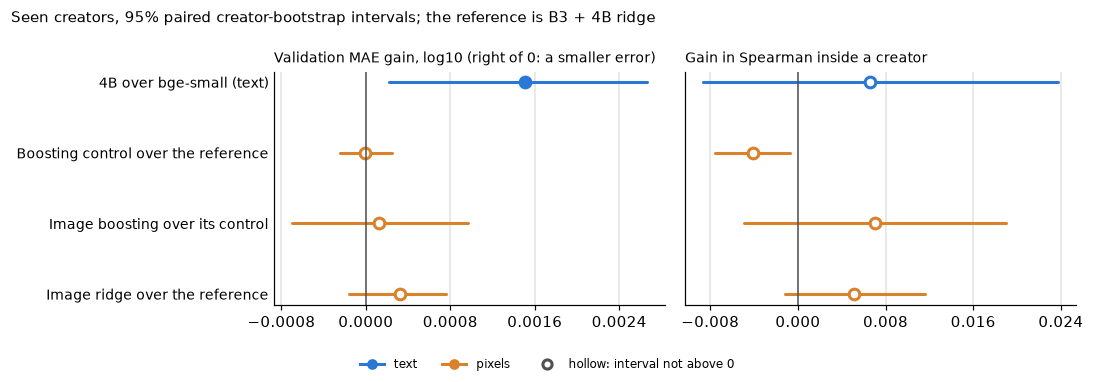

In [16]:
from matplotlib.ticker import MaxNLocator

BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#d9822b", "#52514e", "#e4e3df"  # notebook 03's colours
comparisons = [  # (label, rows, base, model, colour)
    ("4B over bge-small (text)", seen_rows, "bge ridge", "4B ridge", BLUE),
    ("Boosting control over the reference", leak_rows, TEXT, "boosting control", ORANGE),
    ("Image boosting over its control", leak_rows, "boosting control", "image boosting", ORANGE),
    ("Image ridge over the reference", leak_rows, TEXT, "image ridge", ORANGE),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, metric, title in [(axes[0], "MAE", "Validation MAE gain, log10 (right of 0: a smaller error)"),
                          (axes[1], "spearman_within", "Gain in Spearman inside a creator")]:
    for y, (label, rows, base, model, colour) in enumerate(reversed(comparisons)):
        r = paired(metric, rows, base, model)
        ax.plot([r.gain_low, r.gain_high], [y, y], color=colour, linewidth=2, solid_capstyle="round")
        ax.plot(r.gain, y, "o", markersize=7, markeredgewidth=2, color=colour,
                markerfacecolor=colour if r.gain_low > 0 else "white")
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="x", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_locator(MaxNLocator(5))  # few ticks, so their labels never run together
    ax.set_title(title, loc="left", fontsize=9)
axes[0].set_yticks(range(len(comparisons)), [c[0] for c in reversed(comparisons)], fontsize=9)
fig.legend(handles=[
    plt.Line2D([], [], marker="o", color=BLUE, linewidth=2, label="text"),
    plt.Line2D([], [], marker="o", color=ORANGE, linewidth=2, label="pixels"),
    plt.Line2D([], [], marker="o", color=MUTED, markerfacecolor="white", markeredgewidth=2, linestyle="none",
               label="hollow: interval not above 0"),
], loc="lower center", ncol=3, frameon=False, fontsize=8)  # below the panels, clear of every row
fig.suptitle(f"Seen creators, 95% paired creator-bootstrap intervals; the reference is B3 + {TEXT}", x=0.01,
             ha="left", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))  # leave the bottom strip to the legend
plt.show()

**What it says.** The one filled dot is the text: the 4B's MAE gain over bge-small, small and clear of 0. Every pixel
whisker crosses 0 in the MAE panel. In the Spearman panel the boosting control sits just below 0 (−0.004 [−0.008,
−0.001]): bending the reference alone ranks a creator's videos slightly worse. And the 4B's own Spearman gain over
bge-small crosses 0: the larger encoder sizes the typical video better without ranking a creator's videos better.

## What stage 4 found

- **The larger text encoder wins, by a little.** In the same ridge on top of B3, Qwen3-Embedding-4B cuts the seen
  creators' error by 0.0097 [0.0062, 0.0133], 2.6%, against bge-small's 0.0082. Its gain over bge-small, +0.0015
  [+0.0002, +0.0027], clears 0 with and without the reposts, so under the bar written in stage 3 it replaces bge-small.
  It holds for new (+0.0104) and held-out (+0.0089) creators. Over a hundred times the parameters buy 0.4% of the error,
  and no measurable gain in ranking a creator's videos (Spearman 0.224 against 0.218, interval across 0).
- **The first frame adds nothing beyond who made the video and what it says.** On top of B3 and the 4B, SigLIP 2's
  frame vectors gain +0.0003 [−0.0002, +0.0008] in ridge and +0.0001 [−0.0007, +0.0010] in boosting over boosting on
  the reference alone, and neither raises the Spearman inside a creator above 0. Both miss the bar, so the encoder
  isn't fine-tuned and stage 5 leaves the pixels out.
- **The frame knows the creator.** A linear probe on the frozen vectors names a seen creator from the first frame of a
  later video 64.7% of the time [59.5%, 70.3%] (top five: 88.2%), against 9.2% for always guessing the biggest
  creator. What a frame shows most clearly is whose channel it is, and lift is already measured against that channel.
- **The picture's signal was already in the words.** Stage 3 found the scene description, a vision-language model's
  reading of the frames, strong alone but worth only about 0.001 on top of the words. The frame itself, read by an
  image encoder, adds nothing measurable on top of them.
- **One hint, not a finding.** The image models raise the share of breakouts in a seen creator's top tenth from 0.363
  to 0.383 and 0.389, with lower ends just above 0. That metric wasn't part of the bar, the gain doesn't hold for new
  or held-out creators, and among the dozens of intervals here a few clear 0 by chance.
- **Not a leak.** Given a clip's lift, no image model's correction knows whether the platform kept the clip (image
  ridge −0.0007 [−0.0020, +0.0009]). The 38 rows without a frame, from 22 creators, don't differ clearly in lift
  (−0.087 [−0.261, +0.046]).
- **The rental:** 2× RTX 3090, about 3.2 hours by the box's clock, about $0.85 to $1.30 (estimated; the bill wasn't
  read). The 4B text job took 2.1 hours and the frames 1.0 hour on both cards.

The test split was never loaded in this notebook; its texts' and frames' vectors came back from the rental unread.

## The hand-off

**To stage 5: the text, and not the pixels.**

- **Text: Qwen3-Embedding-4B ridge on top of B3,** in place of bge-small (Part A). The features: for each of the seven
  fields, the 4B's first 1,024 numbers for its first 256 tokens (unit length; zeros when the field is empty), plus the
  seven "the field holds text" flags: 7,175 columns. The model: ridge with alpha 100, fitted on the training cell
  (74,552 videos, 148 creators) to what B3 leaves; B3 is notebook 02's (no hour, alpha 0.1). For ranking breakouts, the
  logistic head on B3's standardised prediction and the same columns, C 0.1. `sharerate.heads.RidgeGram` solves the
  ridge (scikit-learn's `Ridge` to 1.8 × 10⁻⁶, cell 11).
- **Pixels: none.** No frozen image model passed, so nothing was fine-tuned and stage 5's combined model leaves the
  frame out. The frame vectors stay on this disk (`data/image_embeddings/`) for a later look; the test's are among them,
  unread.
- **The rows:** the text covers every row (an empty field is zeros with its flag), so stage 5 scores on all rows, and
  no row is lost to a missing frame.

**What stage 5 must compute.**

- **Out-of-fold text predictions for the training rows, if it stacks them.** Section 5 builds exactly these for the
  reference: B3 and the 4B head refitted in 5 folds grouped by creator (`GroupKFold` over the training cell, the
  penalties fixed), each training row predicted by a fit that never saw its creator. In sample the reference misses the
  training rows by 0.3498, out of fold by 0.3600 (cell 23): a stacker fed the in-sample predictions would trust the
  text too much.
- **The test texts' features are already made.** The rental embedded every distinct text of all three splits, blind
  (644,955 in the cache, cell 3). Stage 5 reads the test rows' vectors with `text.embed(..., QWEN, encoder=refuse)`, so
  nothing is embedded on this laptop's CPU and nothing is refitted on the test.
- **For the site:** a text demo that runs in the browser can only use bge-small, not the 4B, so it runs a
  slightly weaker model than the one reported (+0.0082 against +0.0097 for seen creators) and must say so.